# TB1 – Analisis dan Implementasi Klasifikasi Data Menggunakan Perceptron dan ADALINE
**Mata kuliah:** Jaringan Syaraf Tiruan (IT6053) · FTI UKDW  
**Kelompok:** XX · **Anggota:** Sthacya Marela Elsithalia Lakamola (71241106) · Sandy Rehan Linta' (71241144) · Yosiabes Priarsono (71241147)  
**Kasus / dataset:** Kelayakan beli mobil – *Car Evaluation* (UCI), dataset yang sama dengan Tugas 1

**Daftar isi:** 1 Masalah & tujuan · 2 Dataset & kaitan dengan Tugas 1 · 3 Artikel & kode pendukung · 4 Neuron & aturan belajar (+ hitungan manual) · 5 Penyiapan data & rancangan eksperimen · 6 Hasil · 7 Pembahasan & keterbatasan · 8 Kesimpulan · 9 Daftar pustaka


## 1. Masalah dan tujuan
**Masalah.** Pada Tugas 1 kelompok merumuskan kasus: *apakah sebuah mobil layak dipilih calon pembeli berdasarkan enam kriterianya* (harga beli, biaya perawatan, jumlah pintu, kapasitas penumpang, ukuran bagasi, keselamatan), sebagai **supervised learning** klasifikasi 4 kelas dengan MLP. Pada TB1 kasus itu dipersempit menjadi **klasifikasi dua kelas** memakai neuron tunggal: Perceptron dan ADALINE. Masukan **x** ∈ ℝ²¹ (6 fitur kategorikal → one-hot), target y ∈ {−1, +1}, **kelas positif (+1) = `acc` (layak)**, kelas negatif (−1) = `unacc` (tidak layak).

**Tujuan.** (1) Mengimplementasikan Perceptron dan ADALINE (Delta Rule) sendiri dengan NumPy; (2) membandingkan proses belajar keduanya pada 8 konfigurasi terkendali (η, standardisasi); (3) menilai indikasi keterpisahan linear data; (4) menjelaskan hasil berdasarkan bukti, bukan akurasi saja. Seperti dicatat pada Tugas 1, kesalahan paling berbahaya adalah **mobil tidak layak diprediksi layak** — dalam TB1 ini adalah *false positive* kelas `acc`, sehingga **precision kelas positif** menjadi metrik penting di samping recall dan F1.


In [6]:
import sys, platform, warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score

import os
os.makedirs("figures", exist_ok=True); os.makedirs("results", exist_ok=True)
SEED = 42                      # seed tunggal untuk seluruh notebook
np.random.seed(SEED)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 50)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3})

print("Python    :", platform.python_version())
print("NumPy     :", np.__version__, "| pandas:", pd.__version__)
print("scikit-learn:", sklearn.__version__, "| matplotlib:", matplotlib.__version__)
import scipy
print("SciPy     :", scipy.__version__)
print("Seed      :", SEED)


ModuleNotFoundError: No module named 'sklearn'

## 2. Dataset dan kaitannya dengan Tugas 1
* **Sumber:** UCI Machine Learning Repository, *Car Evaluation* (Bohanec & Rajkovic; didonasikan 1997), https://archive.ics.uci.edu/dataset/19/car+evaluation, **lisensi CC BY 4.0**. Tidak ada data pribadi. Data diturunkan dari model keputusan hierarkis DEX (label dari aturan pakar, bukan survei pembeli sungguhan — catatan yang sama dengan Tugas 1).
* **Asal berkas dalam repository (transparansi):** dataset ini **mencakup seluruh 4·4·4·3·3·3 = 1728 kombinasi atribut** dan label adalah fungsi deterministik dari tabel aturan DEX yang dipublikasikan (halaman dataset oleh pembuatnya, lihat bagian 9). Berkas `car_evaluation_full.csv` dibentuk dengan `scripts/rekonstruksi_car_evaluation.py` dari tabel tersebut dan diperiksa terhadap distribusi kelas resmi (unacc 1210, acc 384, good 69, vgood 65). **Keabsahan baris per baris dibuktikan dengan `scripts/verifikasi_car_data.py`**, yang membandingkan berkas ini dengan `car.data` asli dari UCI (hasil verifikasi kelompok dicatat di README). Jika hasilnya berbeda, berkas asli UCI menggantikan berkas ini dan notebook dijalankan ulang.
* **Fitur (6, kategorikal → 21 kolom one-hot, sama seperti Tugas 1):** `buying` {vhigh, high, med, low}, `maint` {vhigh, high, med, low}, `doors` {2, 3, 4, 5more}, `persons` {2, 4, more}, `lug_boot` {small, med, big}, `safety` {low, med, high}.
* **Label asli:** `class` ∈ {unacc, acc, good, vgood} (Tugas 1: 4 kelas, 1210/384/69/65).
* **Pemilihan dua kelas dan alasannya:** dipakai **`unacc` (−1) vs `acc` (+1)**. (i) Keduanya kelas terbesar (1210 dan 384; total **1594 observasi** ≥ 100 yang disarankan); (ii) `good` (69) dan `vgood` (65) terlalu sedikit — pada Tugas 1 jumlahnya hanya ±10 sampel di test set, sehingga metriknya tidak stabil; (iii) keputusan inti kasus ini adalah *layak vs tidak layak dibeli*, dan kesalahan berbahaya (tidak layak → layak) terwakili langsung sebagai false positive `acc`. Konsekuensi: eksperimen ini **bukan** masalah 4 kelas penuh (lihat keterbatasan).
* **Kaitan dengan Tugas 1 yang dipertahankan:** dataset, 6 fitur, one-hot 21 kolom, split berstrata, dan perhatian pada kelas timpang dan pada kesalahan "tidak layak diprediksi layak". **Yang berubah:** model (MLP softmax → neuron tunggal), jumlah kelas (4 → 2), split 70/15/15 → 80:20 (karena TB1 tidak memilih model sehingga tidak butuh validation set).


In [9]:
DATA_PATH, TARGET_COL = "dataset.csv", "class"
POSITIVE, NEGATIVE = "acc", "unacc"          # acc = layak dibeli (+1, positif); unacc = tidak layak (−1)
df = pd.read_csv(DATA_PATH)
full = pd.read_csv("car_evaluation_full.csv")      # 4 kelas asli (hanya untuk deskripsi, tidak dipakai melatih)

print("Dataset penuh Car Evaluation:", full.shape, "| distribusi 4 kelas:", full[TARGET_COL].value_counts().to_dict())
print(f"Dataset eksperimen (2 kelas: {NEGATIVE} vs {POSITIVE}): {df.shape[0]} observasi, 6 fitur kategorikal")
print(f"Missing value: {int(df.isna().sum().sum())} | baris duplikat (seluruh kolom sama): {int(df.duplicated().sum())}")
dist = df[TARGET_COL].value_counts()
print("\nDistribusi kelas eksperimen:")
print(pd.DataFrame({"jumlah": dist, "persen": (100*dist/len(df)).round(1)}))
print(f"Baseline 'selalu {NEGATIVE}': akurasi = {dist[NEGATIVE]/len(df):.4f}")
print("\nNilai unik tiap fitur:")
{c: sorted(df[c].unique().tolist()) for c in df.columns if c != TARGET_COL}


Dataset penuh Car Evaluation: (1728, 7) | distribusi 4 kelas: {'unacc': 1210, 'acc': 384, 'good': 69, 'vgood': 65}
Dataset eksperimen (2 kelas: unacc vs acc): 1594 observasi, 6 fitur kategorikal
Missing value: 0 | baris duplikat (seluruh kolom sama): 0

Distribusi kelas eksperimen:
       jumlah  persen
class                
unacc    1210    75.9
acc       384    24.1
Baseline 'selalu unacc': akurasi = 0.7591

Nilai unik tiap fitur:


{'buying': ['high', 'low', 'med', 'vhigh'],
 'maint': ['high', 'low', 'med', 'vhigh'],
 'doors': ['2', '3', '4', '5more'],
 'persons': ['2', '4', 'more'],
 'lug_boot': ['big', 'med', 'small'],
 'safety': ['high', 'low', 'med']}

Kelas **timpang** (≈ 76 % `unacc` : 24 % `acc`); baseline "selalu `unacc`" sudah mencapai akurasi ±0,759, sehingga akurasi saja menyesatkan dan dilaporkan juga precision, recall, F1 kelas positif. Tidak ada *missing value*; tidak ada baris duplikat (setiap kombinasi atribut muncul sekali), jadi imputasi tidak diperlukan.


## 3. Artikel dan kode pendukung
| Sumber | Jenis | Kontribusi pada pekerjaan ini |
|---|---|---|
| Bohanec & Rajkovic (1990), *Expert system for decision making*, Sistemica 1(1), 145–157 | Artikel ilmiah (kasus) | Asal dataset: model keputusan hierarkis DEX. Dari sini diketahui label berasal dari **aturan bertingkat** (harga → teknis → kelayakan), sehingga kami mengharapkan hubungan fitur–label tidak sepenuhnya aditif/linear; ini kami uji (bagian 6.6) dan bukan diasumsikan. |
| Zupan, Bohanec, Bratko & Demšar (1997), *Machine learning by function decomposition*, ICML-97, 421–429 | Artikel ilmiah (kasus) | Menunjukkan bahwa model hierarkis asli dapat direkonstruksi sepenuhnya dengan dekomposisi fungsi; mendukung dugaan bahwa data bersifat deterministik dan berstruktur (tanpa derau), sehingga galat model linear mencerminkan **keterbatasan kapasitas model**, bukan derau. Model artikel lebih lanjut dari TB1; hanya dipakai sebagai konteks. |
| Rosenblatt (1958); Widrow & Hoff (1960) | Artikel klasik (metode) | Dasar aturan Perceptron dan Delta Rule/LMS. |
| Raschka, *Adaline: Adaptive Linear Neuron Classifier*, dokumentasi mlxtend | Dokumentasi kode | **Diadaptasi:** pola batch gradient descent ADALINE (`e = y − z`, `w += η Xᵀe/n`). **Diubah:** (i) rumus pembaruan dan bias mengikuti panduan tugas; (ii) loss J = (1/2n)Σe² (bukan SSE); (iii) pelatihan dihentikan bila J inf/NaN dan epoch dicatat; (iv) riwayat bobot/akurasi per epoch. Pustaka mlxtend **tidak dipakai** untuk pelatihan. |

*(Kelompok wajib memverifikasi sendiri setiap URL/DOI sebelum pengumpulan.)*


## 4. Model neuron dan aturan pembelajaran
**Neuron (keduanya):** z = wᵀx + b, prediksi ŷ = +1 jika z ≥ 0, ŷ = −1 jika z < 0. Bobot **w** menentukan arah batas keputusan (pada one-hot: bobot per nilai atribut), bias **b** menggeser batasnya (hyperplane wᵀx + b = 0), η adalah laju belajar.

**Perceptron (per sampel, urutan data tetap):** Δ = η(y − ŷ); w ← w + Δ·x; b ← b + Δ. Karena y, ŷ ∈ {±1}, Δ = 0 bila benar dan Δ = ±2η bila salah — **error yang dipakai adalah selisih keluaran *ambang* (diskret)**; jumlah pembaruan salah klasifikasi per epoch dicatat.

**ADALINE (batch, Delta Rule):** error memakai **keluaran linear** z: e = y − z. w ← w + η·Xᵀe/n; b ← b + η·mean(e). Ambang kelas hanya dipakai saat prediksi. Fungsi objektif J = (1/2n)Σ(yᵢ − zᵢ)² (MSE = 2J); **loss dicatat sesudah pembaruan di akhir tiap epoch** (J₀ = sebelum pembaruan pertama).

**Pengaturan umum:** w = 0, b = 0 (inisialisasi nol); urutan sampel tetap seperti pada data latih (tanpa *shuffle*); 50 epoch; η ∈ {0,001; 0,01; 0,1}.


In [10]:
def predict_sign(z):
    """Ambang keputusan: +1 jika z >= 0, selain itu -1."""
    return np.where(z >= 0, 1, -1)

class Perceptron:
    """Perceptron Rosenblatt (NumPy mandiri). Inisialisasi nol, urutan sampel tetap (tanpa shuffle).
    Per sampel: z = w.x + b ; y_hat = sign(z) ; delta = eta*(y - y_hat) ; w += delta*x ; b += delta."""
    def __init__(self, eta=0.01, n_epochs=50):
        self.eta, self.n_epochs = eta, n_epochs

    def net_input(self, X): return X @ self.w_ + self.b_
    def predict(self, X):   return predict_sign(self.net_input(X))

    def fit(self, X, y):
        self.w_, self.b_ = np.zeros(X.shape[1]), 0.0
        self.updates_, self.train_acc_, self.w_hist_, self.b_hist_ = [], [], [], []
        for _ in range(self.n_epochs):
            n_upd = 0
            for xi, yi in zip(X, y):
                y_hat = 1 if (xi @ self.w_ + self.b_) >= 0 else -1
                delta = self.eta * (yi - y_hat)
                if y_hat != yi:                    # pembaruan hanya terjadi bila salah klasifikasi
                    n_upd += 1
                self.w_ += delta * xi
                self.b_ += delta
            self.updates_.append(n_upd)                                  # jumlah pembaruan di epoch ini
            self.train_acc_.append(float(np.mean(self.predict(X) == y))) # akurasi latih di akhir epoch
            self.w_hist_.append(self.w_.copy()); self.b_hist_.append(self.b_)
        return self

class Adaline:
    """ADALINE + Delta Rule, batch gradient descent (NumPy mandiri). Inisialisasi nol.
    Error memakai KELUARAN LINEAR: e = y - z (z = Xw + b). Ambang hanya dipakai saat prediksi.
    w += eta * X^T e / n ; b += eta * mean(e) ; J = (1/2n) sum (y - z)^2 ; MSE = 2J.
    Loss dicatat SESUDAH pembaruan di akhir tiap epoch; J0 = loss awal (sebelum pembaruan pertama).
    Jika J atau parameter menjadi inf/NaN, pelatihan dihentikan dan parameter finite terakhir dipakai."""
    def __init__(self, eta=0.01, n_epochs=50):
        self.eta, self.n_epochs = eta, n_epochs

    def net_input(self, X): return X @ self.w_ + self.b_
    def predict(self, X):   return predict_sign(self.net_input(X))
    @staticmethod
    def cost(X, y, w, b):
        with np.errstate(all="ignore"):
            return 0.5 * np.mean((y - (X @ w + b)) ** 2)

    def fit(self, X, y):
        n = X.shape[0]
        self.w_, self.b_ = np.zeros(X.shape[1]), 0.0
        self.J0_ = self.cost(X, y, self.w_, self.b_)
        self.J_, self.train_acc_, self.w_hist_, self.b_hist_ = [], [], [], []
        self.diverged_epoch_ = None
        for ep in range(1, self.n_epochs + 1):
            with np.errstate(all="ignore"):
                e = y - self.net_input(X)                       # error dari output linear
                w_new = self.w_ + self.eta * (X.T @ e) / n
                b_new = self.b_ + self.eta * e.mean()
            J = self.cost(X, y, w_new, b_new)
            if (not np.isfinite(J)) or (not np.all(np.isfinite(w_new))) or (not np.isfinite(b_new)):
                self.diverged_epoch_ = ep; break                # catat epoch kejadian, hentikan
            self.w_, self.b_ = w_new, b_new
            self.J_.append(J)
            self.train_acc_.append(float(np.mean(self.predict(X) == y)))
            self.w_hist_.append(self.w_.copy()); self.b_hist_.append(self.b_)
        return self


### Perhitungan manual (data mini, η = 0,1, w = [0, 0], b = 0)
Data mini (dua fitur numerik, agar mudah dihitung tangan): x₁ = (1, 2), y₁ = −1; x₂ = (2, 1), y₂ = +1; x₃ = (−1, −1), y₃ = −1; x₄ = (1, −1), y₄ = +1.

**Perceptron – dua sampel pertama**

| Sampel | x | y | z = wᵀx + b | ŷ | Δ = η(y − ŷ) | w sesudah | b sesudah |
|---|---|---|---|---|---|---|---|
| 1 | (1, 2) | −1 | 0·1 + 0·2 + 0 = 0 | +1 (z ≥ 0) | 0,1(−1 − 1) = −0,2 | (0 − 0,2·1, 0 − 0,2·2) = (−0,2; −0,4) | −0,2 |
| 2 | (2, 1) | +1 | −0,4 − 0,4 − 0,2 = −1,0 | −1 | 0,1(1 + 1) = +0,2 | (−0,2 + 0,4; −0,4 + 0,2) = (0,2; −0,2) | −0,2 + 0,2 = 0 |

**Bobot akhir = (0,2; −0,2), bias akhir = 0.**

**ADALINE – dua iterasi batch (n = 4)**

*Iterasi 1:* z = 0 untuk semua → e = y = (−1, 1, −1, 1); J = ½·mean(e²) = 0,5. Xᵀe = (−1+2+1+1, −2+1+1−1) = (3, −1); Xᵀe/n = (0,75; −0,25); mean(e) = 0. w = (0 + 0,1·0,75; 0 + 0,1·(−0,25)) = **(0,075; −0,025)**, b = 0 + 0,1·0 = **0**. J sesudah = 0,441094.

*Iterasi 2:* z = Xw + b = (0,025; 0,125; −0,05; 0,1) → e = y − z = (−1,025; 0,875; −0,95; 0,9). Xᵀe = (−1,025 + 1,75 + 0,95 + 0,9; −2,05 + 0,875 + 0,95 − 0,9) = (2,575; −1,125); Xᵀe/n = (0,64375; −0,28125); mean(e) = −0,05. w = (0,075 + 0,064375; −0,025 − 0,028125) = **(0,139375; −0,053125)**, b = 0 + 0,1·(−0,05) = **−0,005**. J sesudah = 0,393806.

**Bobot akhir = (0,139375; −0,053125), bias akhir = −0,005.** Sel di bawah menjalankan langkah yang sama dengan kode dan memverifikasi (`assert`) bahwa hasilnya cocok dengan hitungan tangan di atas serta dengan kelas `Perceptron` dan `Adaline`.


In [11]:
# Data mini untuk hitungan manual (2 fitur, 4 sampel), eta = 0.1, w = [0,0], b = 0
Xm = np.array([[ 1.,  2.], [ 2.,  1.], [-1., -1.], [ 1., -1.]])
ym = np.array([-1., 1., -1., 1.])
eta_m = 0.1

# --- Perceptron: dua sampel pertama, dilacak langkah demi langkah ---
w, b = np.zeros(2), 0.0
print("PERCEPTRON (eta=0.1)")
for k in range(2):
    z = Xm[k] @ w + b; yh = 1 if z >= 0 else -1; d = eta_m * (ym[k] - yh)
    print(f" sampel {k+1}: x={Xm[k]}, y={ym[k]:+.0f} | z={z:+.2f}, y_hat={yh:+d}, delta={d:+.2f}", end="")
    w = w + d * Xm[k]; b = b + d
    print(f" -> w={w}, b={b:+.2f}")
w_manual_p, b_manual_p = np.array([0.2, -0.2]), 0.0           # hasil hitung tangan (lihat sel markdown)
assert np.allclose(w, w_manual_p) and np.isclose(b, b_manual_p)

# Konsistensi dengan kelas Perceptron: satu epoch tetapi hanya 2 sampel pertama
pm = Perceptron(eta_m, 1).fit(Xm[:2], ym[:2])
assert np.allclose(pm.w_, w_manual_p) and np.isclose(pm.b_, b_manual_p)
print("  Kelas Perceptron (2 sampel) cocok dengan hitungan manual.")

# --- ADALINE: dua iterasi batch (n = 4) ---
w, b = np.zeros(2), 0.0
print("\nADALINE batch (eta=0.1)")
for it in (1, 2):
    z = Xm @ w + b; e = ym - z
    J_before = 0.5 * np.mean(e**2)
    gw, gb = Xm.T @ e / len(ym), e.mean()
    w, b = w + eta_m * gw, b + eta_m * gb
    J_after = Adaline.cost(Xm, ym, w, b)
    print(f" iterasi {it}: z={np.round(z,4)}, e={np.round(e,4)}, X^T e/n={np.round(gw,4)}, mean(e)={gb:+.4f}")
    print(f"    J sebelum={J_before:.6f} -> w={np.round(w,6)}, b={b:+.6f}, J sesudah={J_after:.6f}")
w_manual_a, b_manual_a = np.array([0.139375, -0.053125]), -0.005       # hasil hitung tangan
assert np.allclose(w, w_manual_a) and np.isclose(b, b_manual_a)
am = Adaline(eta_m, 2).fit(Xm, ym)
assert np.allclose(am.w_, w_manual_a) and np.isclose(am.b_, b_manual_a)
print("  Kelas Adaline (2 epoch) cocok dengan hitungan manual.")


PERCEPTRON (eta=0.1)
 sampel 1: x=[1. 2.], y=-1 | z=+0.00, y_hat=+1, delta=-0.20 -> w=[-0.2 -0.4], b=-0.20
 sampel 2: x=[2. 1.], y=+1 | z=-1.00, y_hat=-1, delta=+0.20 -> w=[ 0.2 -0.2], b=+0.00
  Kelas Perceptron (2 sampel) cocok dengan hitungan manual.

ADALINE batch (eta=0.1)
 iterasi 1: z=[0. 0. 0. 0.], e=[-1.  1. -1.  1.], X^T e/n=[ 0.75 -0.25], mean(e)=+0.0000
    J sebelum=0.500000 -> w=[ 0.075 -0.025], b=+0.000000, J sesudah=0.441094
 iterasi 2: z=[ 0.025  0.125 -0.05   0.1  ], e=[-1.025  0.875 -0.95   0.9  ], X^T e/n=[ 0.6438 -0.2812], mean(e)=-0.0500
    J sebelum=0.441094 -> w=[ 0.139375 -0.053125], b=-0.005000, J sesudah=0.393806
  Kelas Adaline (2 epoch) cocok dengan hitungan manual.


## 5. Penyiapan data dan rancangan eksperimen
* **Pengodean:** 6 fitur kategorikal → **21 kolom one-hot (0/1)**; domain nilai tiap atribut tetap (ditentukan definisi dataset, bukan dipelajari dari data) sehingga tidak ada kebocoran. Label: `acc` → +1, `unacc` → −1.
* **Split:** 80 : 20 **berstratifikasi** kelas, `random_state = 42`; **split yang sama** untuk semua model dan konfigurasi.
* **Tanpa kebocoran:** rata-rata dan simpangan baku standardisasi dipelajari **hanya dari data latih**, lalu diterapkan ke data uji.
* **Konfigurasi ditetapkan sebelum evaluasi uji** (8 pelatihan): Perceptron dan ADALINE × η ∈ {0,001; 0,01; 0,1} dengan standardisasi, ditambah satu pelatihan tanpa standardisasi per model (η = 0,01). Semua 50 epoch, inisialisasi nol, urutan sampel sama.
* **Data uji hanya untuk pelaporan** semua konfigurasi di atas. **Tidak ada pemilihan model/parameter terbaik** sehingga data validasi tidak diperlukan; tidak ada η yang dicoba berulang kali pada data uji. Diagnostik di bagian 6.5–6.6 memakai **data latih saja**.
* Jika J atau parameter ADALINE menjadi inf/NaN, pelatihan dihentikan, epoch dicatat, dan parameter finite terakhir dipakai untuk evaluasi.


In [12]:
# Domain nilai tiap atribut adalah tetap (ditetapkan oleh definisi dataset, bukan dipelajari dari data),
# sehingga pembentukan kolom one-hot tidak menimbulkan kebocoran data.
DOMAIN = {"buying": ["vhigh", "high", "med", "low"], "maint": ["vhigh", "high", "med", "low"],
          "doors": ["2", "3", "4", "5more"], "persons": ["2", "4", "more"],
          "lug_boot": ["small", "med", "big"], "safety": ["low", "med", "high"]}
def one_hot(frame):
    cols, names = [], []
    for a, vals in DOMAIN.items():
        v = frame[a].astype(str).to_numpy()
        for val in vals:
            cols.append((v == val).astype(float)); names.append(f"{a}={val}")
    return np.column_stack(cols), names
X, feature_cols = one_hot(df)                      # 6 fitur kategorikal -> 21 kolom 0/1
y = np.where(df[TARGET_COL].to_numpy() == POSITIVE, 1, -1)   # acc -> +1 (positif), unacc -> -1
assert not np.isnan(X).any() and np.all(X.sum(1) == 6)       # tiap sampel punya tepat 6 kolom aktif

# Split 80:20 berstratifikasi, seed tercatat. Dipakai identik oleh SEMUA model/konfigurasi.
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)
# Standardisasi: mean & std HANYA dari data latih, lalu diterapkan ke data uji (tanpa kebocoran).
# (Tidak ada missing value -> imputasi tidak diperlukan.)
scaler = StandardScaler().fit(Xtr)
Xtr_s, Xte_s = scaler.transform(Xtr), scaler.transform(Xte)

print(f"X: {X.shape} (21 kolom one-hot: {', '.join(feature_cols[:4])}, ...)")
print(f"Latih: {Xtr.shape}  (+1: {(ytr==1).sum()}, -1: {(ytr==-1).sum()}, proporsi +1 = {np.mean(ytr==1):.3f})")
print(f"Uji  : {Xte.shape}  (+1: {(yte==1).sum()}, -1: {(yte==-1).sum()}, proporsi +1 = {np.mean(yte==1):.3f})")
print(f"Baseline uji 'selalu −1' = {np.mean(yte==-1):.4f}")
print(f"Standardisasi (latih): mean maks |.| = {np.abs(Xtr_s.mean(0)).max():.1e}; std kolom mentah {Xtr.std(0).min():.3f}..{Xtr.std(0).max():.3f} -> 1.0")


NameError: name 'train_test_split' is not defined

In [6]:
N_EPOCHS = 50
CONFIGS = [  # (model, eta, standardisasi) -- ditetapkan SEBELUM menyentuh data uji
    ("Perceptron", 0.001, True), ("Perceptron", 0.01, True), ("Perceptron", 0.1, True),
    ("ADALINE",    0.001, True), ("ADALINE",    0.01, True), ("ADALINE",    0.1, True),
    ("Perceptron", 0.01, False), ("ADALINE",    0.01, False),
]
runs = []
for name, eta, std in CONFIGS:
    Xa = Xtr_s if std else Xtr                      # data latih yang sama, hanya skalanya berbeda
    model = (Perceptron if name == "Perceptron" else Adaline)(eta=eta, n_epochs=N_EPOCHS).fit(Xa, ytr)
    runs.append(dict(name=name, eta=eta, std=std, model=model,
                     key=f"{name} η={eta} {'std' if std else 'raw'}"))
    msg = f"[{runs[-1]['key']:<26}] akurasi latih = {np.mean(model.predict(Xa)==ytr):.4f}"
    if name == "ADALINE":
        msg += f" | J0 = {model.J0_:.4f}" + (f" | DIVERGEN pada epoch {model.diverged_epoch_}" if model.diverged_epoch_ else f" | J akhir = {model.J_[-1]:.4f}")
    else:
        msg += f" | pembaruan epoch-50 = {model.updates_[-1]}"
    print(msg)


[Perceptron η=0.001 std    ] akurasi latih = 0.9200 | pembaruan epoch-50 = 97


[Perceptron η=0.01 std     ] akurasi latih = 0.9200 | pembaruan epoch-50 = 97


[Perceptron η=0.1 std      ] akurasi latih = 0.9200 | pembaruan epoch-50 = 97
[ADALINE η=0.001 std       ] akurasi latih = 0.8988 | J0 = 0.5000 | J akhir = 0.4663
[ADALINE η=0.01 std        ] akurasi latih = 0.9169 | J0 = 0.5000 | J akhir = 0.2903
[ADALINE η=0.1 std         ] akurasi latih = 0.9412 | J0 = 0.5000 | J akhir = 0.1938


[Perceptron η=0.01 raw     ] akurasi latih = 0.9043 | pembaruan epoch-50 = 105
[ADALINE η=0.01 raw        ] akurasi latih = 0.7592 | J0 = 0.5000 | J akhir = 0.3279


## 6. Hasil
### 6.1 Tabel seluruh konfigurasi
Akurasi diukur pada keluaran ambang. Perceptron: "galat latih akhir" = 1 − akurasi latih setelah epoch 50; "pembaruan epoch-50" = jumlah pembaruan salah klasifikasi pada epoch ke-50. ADALINE: J akhir = J sesudah pembaruan epoch ke-50 (MSE = 2J). Tabel disimpan di `results/hasil_konfigurasi.csv`. *Baseline "selalu unacc": akurasi uji 0,7586.*


In [7]:
rows = []
for r in runs:
    m = r["model"]; Xa, Xb = (Xtr_s, Xte_s) if r["std"] else (Xtr, Xte)   # data uji hanya dipakai di sini (laporan akhir)
    tr, te = np.mean(m.predict(Xa) == ytr), np.mean(m.predict(Xb) == yte)
    cm = confusion_matrix(yte, m.predict(Xb), labels=[1, -1])            # baris: aktual [+1,-1]; kolom: prediksi [+1,-1]
    r.update(cm=cm, pred_te=m.predict(Xb), acc_tr=tr, acc_te=te)
    row = {"Model": r["name"], "η": r["eta"], "Epoch": N_EPOCHS, "Standardisasi": "Ya" if r["std"] else "Tidak",
           "Akurasi latih": round(tr, 4), "Akurasi uji": round(te, 4), "Galat latih akhir": round(1-tr, 4)}
    if r["name"] == "Perceptron":
        row.update({"Pembaruan epoch-50": m.updates_[-1], "J akhir": np.nan, "MSE akhir": np.nan, "Epoch divergen": "-"})
    else:
        J = m.J_[-1] if m.J_ else np.nan
        row.update({"Pembaruan epoch-50": np.nan, "J akhir": J, "MSE akhir": 2*J, "Epoch divergen": m.diverged_epoch_ or "-"})
    rows.append(row)
res = pd.DataFrame(rows)
res.to_csv("results/hasil_konfigurasi.csv", index=False)
fmt = res.copy()
for c in ["J akhir", "MSE akhir"]:
    fmt[c] = fmt[c].map(lambda v: "–" if pd.isna(v) else f"{v:.4g}")
fmt["Pembaruan epoch-50"] = fmt["Pembaruan epoch-50"].map(lambda v: "–" if pd.isna(v) else f"{int(v)}")
fmt


,Model,η,Epoch,Standardisasi,Akurasi latih,Akurasi uji,Galat latih akhir,Pembaruan epoch-50,J akhir,MSE akhir,Epoch divergen
0,Perceptron,0.001,50,Ya,0.9200,0.9028,0.0800,97,–,–,-
1,Perceptron,0.010,50,Ya,0.9200,0.9028,0.0800,97,–,–,-
2,Perceptron,0.100,50,Ya,0.9200,0.9028,0.0800,97,–,–,-
3,ADALINE,0.001,50,Ya,0.8988,0.8683,0.1012,–,0.4663,0.9325,-
4,ADALINE,0.010,50,Ya,0.9169,0.8934,0.0831,–,0.2903,0.5806,-
5,ADALINE,0.100,50,Ya,0.9412,0.9467,0.0588,–,0.1938,0.3876,-
6,Perceptron,0.010,50,Tidak,0.9043,0.8746,0.0957,105,–,–,-
7,ADALINE,0.010,50,Tidak,0.7592,0.7586,0.2408,–,0.3279,0.6558,-


### 6.2 Kondisi pada epoch ke-10, ke-30, dan ke-50
Perceptron: jumlah pembaruan salah klasifikasi pada epoch tersebut; ADALINE: J sesudah pembaruan; akurasi latih diukur di akhir epoch. (`–` = pelatihan sudah berhenti sebelum epoch itu; tidak terjadi pada eksperimen ini.)


In [8]:
def at(hist, ep):                       # nilai riwayat pada epoch ke-ep (NaN jika pelatihan sudah berhenti)
    return hist[ep-1] if len(hist) >= ep else np.nan
snap = []
for r in runs:
    m = r["model"]; h = m.updates_ if r["name"] == "Perceptron" else m.J_
    for ep in (10, 30, 50):
        snap.append({"Konfigurasi": r["key"], "Epoch": ep,
                     "Pembaruan salah / J (sesudah update)": at(h, ep), "Akurasi latih": at(m.train_acc_, ep)})
snap = pd.DataFrame(snap)
snap_wide = snap.pivot(index="Konfigurasi", columns="Epoch", values=["Pembaruan salah / J (sesudah update)", "Akurasi latih"])
snap_wide = snap_wide.reindex([r["key"] for r in runs])
snap_wide.round(4).to_csv("results/riwayat_epoch_10_30_50.csv")
snap_wide.map(lambda v: "–" if pd.isna(v) else f"{v:.4g}")


Pembaruan salah / J (sesudah update)                 Akurasi latih                
Epoch                                                    10      30      50            10      30      50
Konfigurasi                                                                                              
Perceptron η=0.001 std                                   96      97      97        0.9255    0.92    0.92
Perceptron η=0.01 std                                    96      97      97        0.9255    0.92    0.92
Perceptron η=0.1 std                                     96      97      97        0.9255    0.92    0.92
ADALINE η=0.001 std                                  0.4929  0.4793  0.4663        0.8973   0.898  0.8988
ADALINE η=0.01 std                                    0.436  0.3462  0.2903        0.9004  0.9098  0.9169
ADALINE η=0.1 std                                    0.2218  0.1941  0.1938        0.9333  0.9404  0.9412
Perceptron η=0.01 raw                                    98      99     105        0.9325  0.9325  0.9043
ADALINE η=0.01 raw                                   0.4312  0.3607  0.3279        0.7592  0.7592  0.7592

### 6.3 Confusion matrix, precision, recall, F1 (kelas positif = `acc`, +1)
Urutan label: **[+1 (acc), −1 (unacc)]**; baris = aktual, kolom = prediksi. TP = acc terdeteksi acc, FN = acc terlewat, **FP = unacc dikira acc (kesalahan berbahaya)**, TN = unacc benar. Precision = TP/(TP+FP) bernilai 0 bila model tidak pernah memprediksi +1.


In [1]:
fig, axes = plt.subplots(2, 4, figsize=(15, 6.8))
for ax, r in zip(axes.ravel(), runs):
    cm = r["cm"]
    ax.imshow(cm, cmap="Blues"); ax.grid(False)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=14, color="white" if cm[i, j] > cm.max()/2 else "black")
    ax.set_xticks([0, 1], ["+1 (acc)", "−1 (unacc)"]); ax.set_yticks([0, 1], ["+1 (acc)", "−1 (unacc)"])
    ax.set_xlabel("Prediksi"); ax.set_ylabel("Aktual"); ax.set_title(f"{r['key']}\nuji acc={r['acc_te']:.3f}", fontsize=9)
plt.suptitle("Confusion matrix data uji (baris = aktual, kolom = prediksi; urutan label: +1 (acc), −1 (unacc))", y=1.0)
plt.tight_layout(); plt.savefig("figures/confusion_matrix_8_konfigurasi.png", bbox_inches="tight"); plt.show()

rows = []
for r in runs:
    (tp, fn), (fp, tn) = r["cm"]
    rows.append({"Konfigurasi": r["key"], "TP": tp, "FN": fn, "FP": fp, "TN": tn,
                 "Precision (+1)": precision_score(yte, r["pred_te"], pos_label=1, zero_division=0),
                 "Recall (+1)": recall_score(yte, r["pred_te"], pos_label=1, zero_division=0),
                 "F1 (+1)": f1_score(yte, r["pred_te"], pos_label=1, zero_division=0)})
metrics = pd.DataFrame(rows); metrics.round(4).to_csv("results/metrik_kelas_positif.csv", index=False)
metrics.round(4)


NameError: name 'plt' is not defined

### 6.4 Kurva pelatihan (hingga epoch ke-50)


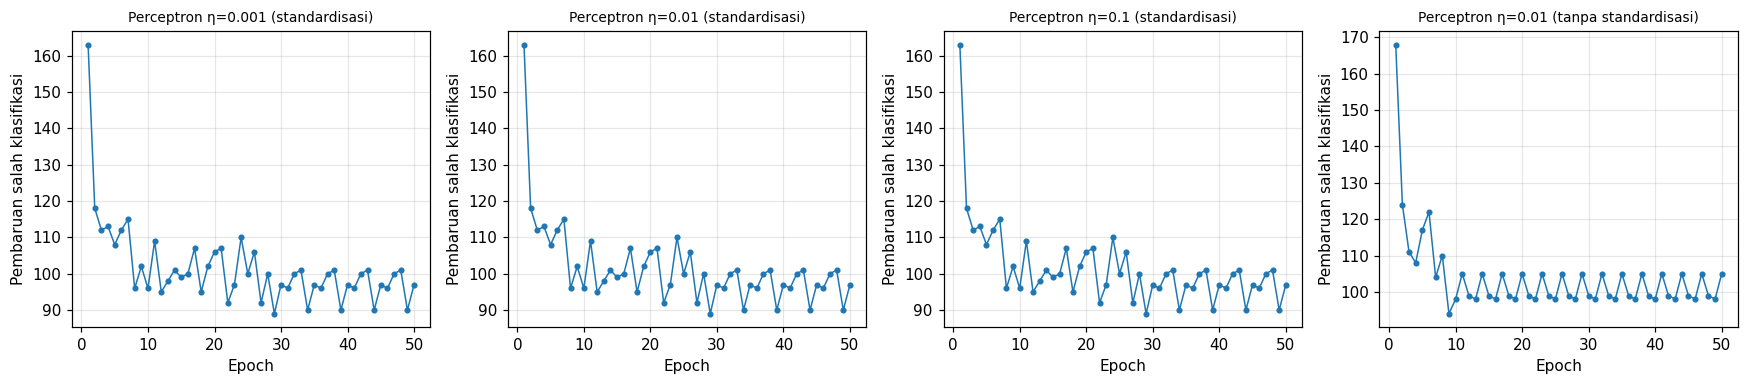

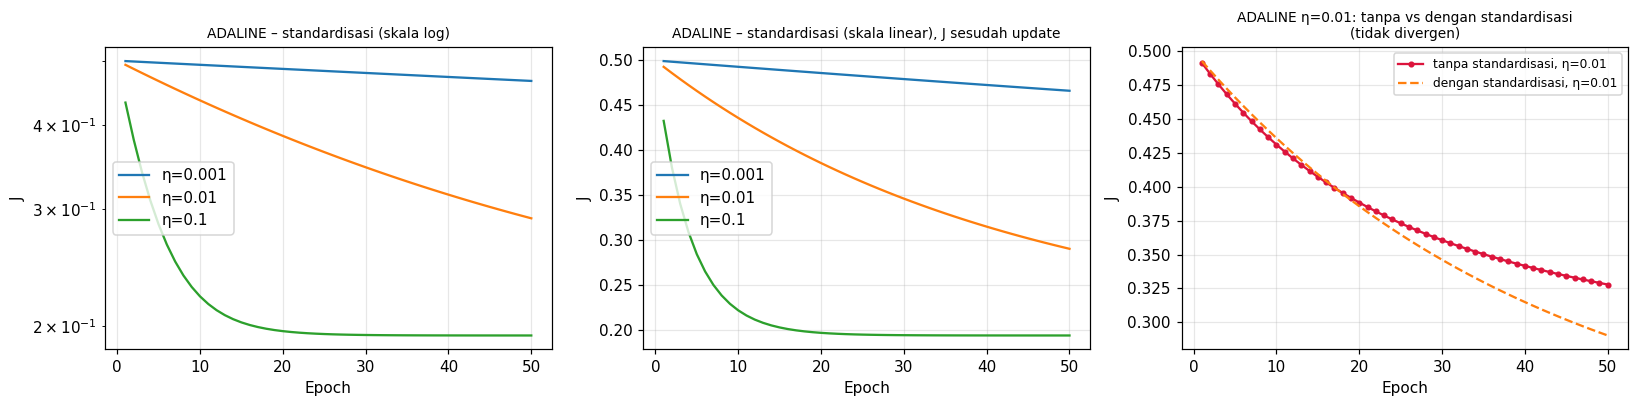

Kesalahan latih setelah epoch terakhir (1 - akurasi latih):
{'Perceptron η=0.001 std': np.float64(0.08), 'Perceptron η=0.01 std': np.float64(0.08), 'Perceptron η=0.1 std': np.float64(0.08), 'ADALINE η=0.001 std': np.float64(0.1012), 'ADALINE η=0.01 std': np.float64(0.0831), 'ADALINE η=0.1 std': np.float64(0.0588), 'Perceptron η=0.01 raw': np.float64(0.0957), 'ADALINE η=0.01 raw': np.float64(0.2408)}


In [10]:
P = {(r["eta"], r["std"]): r for r in runs if r["name"] == "Perceptron"}
A = {(r["eta"], r["std"]): r for r in runs if r["name"] == "ADALINE"}
ep = np.arange(1, N_EPOCHS + 1)

fig, axes = plt.subplots(1, 4, figsize=(16, 3.6), sharey=False)
for ax, (key, r) in zip(axes, P.items()):
    ax.plot(ep, r["model"].updates_, marker=".", lw=1)
    ax.set_title(f"Perceptron η={key[0]} ({'standardisasi' if key[1] else 'tanpa standardisasi'})", fontsize=9)
    ax.set_xlabel("Epoch"); ax.set_ylabel("Pembaruan salah klasifikasi")
plt.tight_layout(); plt.savefig("figures/kurva_perceptron.png", bbox_inches="tight"); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for key, r in A.items():
    if key[1]:
        axes[0].plot(ep[:len(r["model"].J_)], r["model"].J_, label=f"η={key[0]}")
axes[0].set_yscale("log"); axes[0].set_title("ADALINE – standardisasi (skala log)", fontsize=9)
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("J"); axes[0].legend()
for key, r in A.items():
    if key[1]:
        axes[1].plot(ep[:len(r["model"].J_)], r["model"].J_, label=f"η={key[0]}")
axes[1].set_title("ADALINE – standardisasi (skala linear), J sesudah update", fontsize=9); axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("J"); axes[1].legend()
raw = A[(0.01, False)]["model"]
axes[2].plot(np.arange(1, len(raw.J_) + 1), raw.J_, marker="o", ms=3, color="crimson", label="tanpa standardisasi, η=0.01")
Jstd = A[(0.01, True)]["model"].J_
axes[2].plot(np.arange(1, len(Jstd) + 1), Jstd, color="tab:orange", ls="--", label="dengan standardisasi, η=0.01")
axes[2].set_xlabel("Epoch"); axes[2].set_ylabel("J"); axes[2].legend(fontsize=8)
axes[2].set_title("ADALINE η=0.01: tanpa vs dengan standardisasi" + (f"\ndivergen: inf/NaN pada epoch {raw.diverged_epoch_}" if raw.diverged_epoch_ else "\n(tidak divergen)"), fontsize=9)
plt.tight_layout(); plt.savefig("figures/kurva_adaline.png", bbox_inches="tight"); plt.show()
print("Kesalahan latih setelah epoch terakhir (1 - akurasi latih):")
print({r["key"]: round(1 - r["acc_tr"], 4) for r in runs})


### 6.5 Bobot, bias akhir, dan pembanding teoretis
Bobot dan bias akhir semua konfigurasi disimpan di `results/bobot_bias_akhir.csv`. Sel berikutnya menghitung (pada data latih) **solusi kuadrat terkecil bentuk tertutup** (J\*, nilai J terendah yang bisa dicapai ADALINE) serta **batas kestabilan** η < 2/λmax dan kondisi numerik κ untuk batch gradient descent.


In [11]:
W = pd.DataFrame({r["key"]: np.append(r["model"].w_, r["model"].b_) for r in runs}, index=feature_cols + ["bias b"])
W.to_csv("results/bobot_bias_akhir.csv")
summ = pd.DataFrame({r["key"]: {"bias b": r["model"].b_, "||w||₂": np.linalg.norm(r["model"].w_)} for r in runs}).T
print("Ringkasan bobot & bias akhir (semua 8 konfigurasi); tabel lengkap 21 bobot + bias di results/bobot_bias_akhir.csv")
print(summ.to_string(float_format=lambda v: f"{v:.4g}"))

# Bukti: pada Perceptron (w0=0, urutan tetap, eta>0 konstan) mengubah eta hanya menskalakan w dan b.
w1, w2, w3 = (P[(e, True)]["model"] for e in (0.001, 0.01, 0.1))
print("\nPerceptron std: w(η=0.01)/w(η=0.001) =", np.unique(np.round(w2.w_[np.abs(w1.w_) > 1e-12] / w1.w_[np.abs(w1.w_) > 1e-12], 6)),
      "| w(η=0.1)/w(η=0.001) =", np.unique(np.round(w3.w_[np.abs(w1.w_) > 1e-12] / w1.w_[np.abs(w1.w_) > 1e-12], 6)))
print("Prediksi uji identik untuk tiga η Perceptron:", np.array_equal(P[(0.001,True)]["pred_te"], P[(0.01,True)]["pred_te"]) and np.array_equal(P[(0.01,True)]["pred_te"], P[(0.1,True)]["pred_te"]))

top = W[[r["key"] for r in runs if r["eta"] == 0.01 and r["std"]]].drop("bias b")
top = top.reindex(top.abs().sum(axis=1).sort_values(ascending=False).index).head(6)
print("\nEnam fitur dengan |bobot| terbesar (η=0.01, standardisasi):"); top


Ringkasan bobot & bias akhir (semua 8 konfigurasi); tabel lengkap 21 bobot + bias di results/bobot_bias_akhir.csv
                        bias b  ||w||₂
Perceptron η=0.001 std  -0.086 0.09681
Perceptron η=0.01 std    -0.86  0.9681
Perceptron η=0.1 std      -8.6   9.681
ADALINE η=0.001 std    -0.0253 0.03237
ADALINE η=0.01 std     -0.2048  0.2458
ADALINE η=0.1 std      -0.5158  0.5192
Perceptron η=0.01 raw    -0.06  0.7009
ADALINE η=0.01 raw     -0.1401  0.2416

Perceptron std: w(η=0.01)/w(η=0.001) = [10.] | w(η=0.1)/w(η=0.001) = [100.]
Prediksi uji identik untuk tiga η Perceptron: True

Enam fitur dengan |bobot| terbesar (η=0.01, standardisasi):


,Perceptron η=0.01 std,ADALINE η=0.01 std
persons=2,-0.524981,-0.130965
safety=low,-0.511798,-0.132594
safety=high,0.303010,0.093098
persons=more,0.292347,0.063337
persons=4,0.246958,0.071214
safety=med,0.227572,0.044762


In [12]:
# Pembanding teoretis (HANYA data latih): solusi kuadrat terkecil bentuk tertutup memberi J* = nilai J
# terendah yang dapat dicapai ADALINE linear; batas kestabilan batch GD: η < 2/λmax(H), H = [X 1]ᵀ[X 1]/n.
def aug(Xa): return np.hstack([Xa, np.ones((len(Xa), 1))])
def J_star(Xa):
    Xb = aug(Xa); wls, *_ = np.linalg.lstsq(Xb, ytr.astype(float), rcond=None)
    return 0.5 * np.mean((ytr - Xb @ wls) ** 2)
def eigs(Xa):
    Xb = aug(Xa); e = np.linalg.eigvalsh(Xb.T @ Xb / len(Xb)); return e[e > 1e-10]   # eigenvalue > 0 (one-hot -> ada arah nol)
lam_max = lambda Xa: eigs(Xa).max()
ls = pd.DataFrame({"J* (kuadrat terkecil)": [J_star(Xtr_s), J_star(Xtr)], "λmax(H)": [lam_max(Xtr_s), lam_max(Xtr)], "λmin>0(H)": [eigs(Xtr_s).min(), eigs(Xtr).min()]},
                  index=["standardisasi", "tanpa standardisasi"])
ls["batas η = 2/λmax"] = 2 / ls["λmax(H)"]
ls["κ = λmax/λmin"] = ls["λmax(H)"] / ls["λmin>0(H)"]
ls["J ADALINE epoch 50 (η=0.1 / η=0.01)"] = [f"{A[(0.1, True)]['model'].J_[-1]:.4f}", f"{A[(0.01, False)]['model'].J_[-1]:.4f}"]
print("Seluruh η yang dipakai pada data standardisasi (0.001, 0.01, 0.1) < batas?", all(e < ls.loc['standardisasi', 'batas η = 2/λmax'] for e in (0.001, 0.01, 0.1)))
print("η = 0.01 pada data tanpa standardisasi < batas?", 0.01 < ls.loc["tanpa standardisasi", "batas η = 2/λmax"])
ls.round(4)


Seluruh η yang dipakai pada data standardisasi (0.001, 0.01, 0.1) < batas? True
η = 0.01 pada data tanpa standardisasi < batas? True


,J* (kuadrat terkecil),λmax(H),λmin>0(H),batas η = 2/λmax,κ = λmax/λmin,J ADALINE epoch 50 (η=0.1 / η=0.01)
standardisasi,0.1938,1.6705,1.0000,1.1973,1.6705,0.1938
tanpa standardisasi,0.1938,2.7577,0.2073,0.7252,13.3040,0.3279


### 6.6 Batas keputusan dan indikasi keterpisahan linear
Dengan **21 fitur one-hot**, batas keputusan adalah hyperplane berdimensi 20; menggambarnya pada bidang dua fitur tidak bermakna (fitur biner hanya membentuk beberapa titik). Proyeksi yang **setia** adalah **skor z = wᵀx + b**: batas keputusan tepat berada di z = 0, sehingga histogram z per kelas menunjukkan di mana kedua kelas tumpang tindih. Panel kanan menunjukkan bobot ADALINE per nilai atribut.


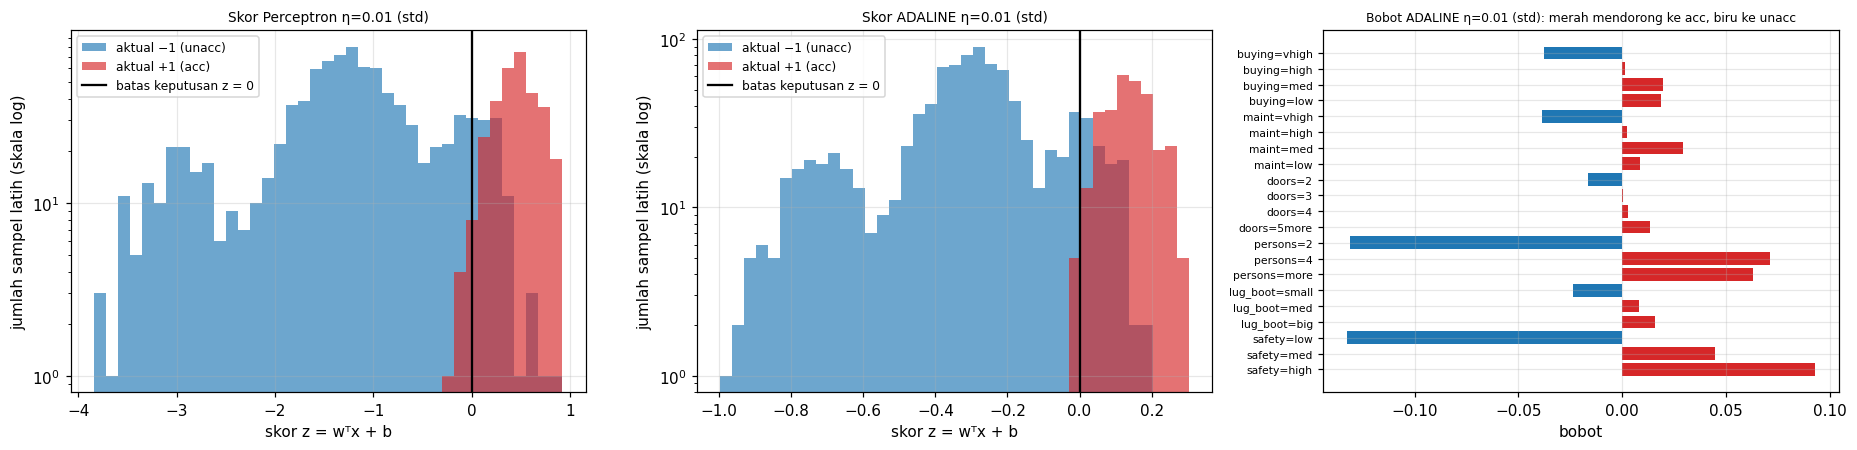

Bias ADALINE: -0.2048 | bias Perceptron: -0.86


In [13]:
# Dengan 21 fitur one-hot, batas keputusan adalah hyperplane berdimensi 20 dan TIDAK dapat digambar langsung
# pada bidang dua fitur (fitur biner hanya menghasilkan beberapa titik). Proyeksi yang setia: skor z = wᵀx + b,
# karena batas keputusan tepat berada di z = 0 (sumbu mendatar di bawah). Titik-titik dihitung pada data latih.
mP, mA = P[(0.01, True)]["model"], A[(0.01, True)]["model"]
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
for ax, m, t in ((axes[0], mP, "Perceptron η=0.01 (std)"), (axes[1], mA, "ADALINE η=0.01 (std)")):
    z = m.net_input(Xtr_s)
    bins = np.linspace(z.min(), z.max(), 40)
    ax.hist(z[ytr == -1], bins=bins, alpha=.65, color="tab:blue", label="aktual −1 (unacc)")
    ax.hist(z[ytr == 1],  bins=bins, alpha=.65, color="tab:red",  label="aktual +1 (acc)")
    ax.axvline(0, color="k", lw=1.5, label="batas keputusan z = 0"); ax.set_yscale("log")
    ax.set_xlabel("skor z = wᵀx + b"); ax.set_ylabel("jumlah sampel latih (skala log)"); ax.set_title(f"Skor {t}", fontsize=9); ax.legend(fontsize=8)
# bobot ADALINE η=0.01 per nilai fitur (ruang terstandardisasi)
order = np.arange(len(feature_cols)); colors = ["tab:red" if w > 0 else "tab:blue" for w in mA.w_]
axes[2].barh(order, mA.w_, color=colors); axes[2].set_yticks(order, feature_cols, fontsize=7); axes[2].invert_yaxis()
axes[2].set_title("Bobot ADALINE η=0.01 (std): merah mendorong ke acc, biru ke unacc", fontsize=8); axes[2].set_xlabel("bobot")
plt.tight_layout(); plt.savefig("figures/skor_dan_bobot.png", bbox_inches="tight"); plt.show()
print("Bias ADALINE:", round(mA.b_, 4), "| bias Perceptron:", round(mP.b_, 4))


**Diagnostik keterpisahan (hanya data latih).** (1) Perceptron dijalankan 2000 epoch; (2) **uji pasti** memakai linear programming: mencari (w, b) dengan yᵢ(wᵀxᵢ + b) ≥ 1 untuk semua sampel latih — layak jika dan hanya jika data latih terpisah linear. Ini bukan konfigurasi utama dan tidak dipakai untuk memilih model.


Perceptron 2000 epoch (data latih terstandardisasi):
  pembaruan epoch 1 = 163, epoch 50 = 97, minimum = 89 (epoch 29), epoch 2000 = 97
  akurasi latih tertinggi sepanjang epoch: 0.9396

Uji pasti (linear programming) pada data latih one-hot: status = 'The problem is infeasible. (HiGHS Status 8: model_status is '
  -> data latih TIDAK terpisah linear (tidak ada hyperplane yang benar untuk semua sampel latih)


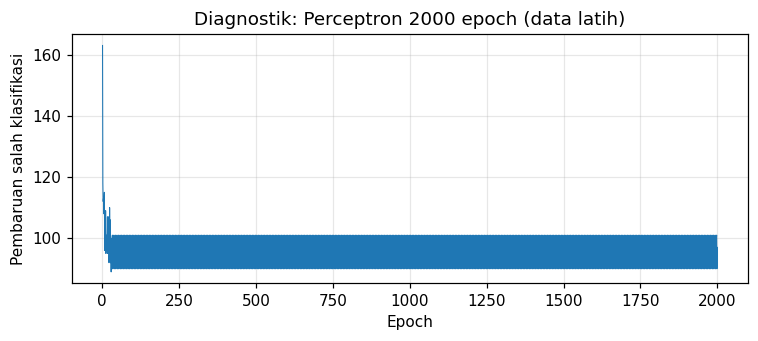

In [14]:
# Diagnostik keterpisahan linear -- HANYA data latih (data uji tidak disentuh).
# (1) Perceptron 2000 epoch; (2) uji pasti dengan pemrograman linear (layak <=> terpisah linear).
from scipy.optimize import linprog
diag = Perceptron(eta=0.01, n_epochs=2000).fit(Xtr_s, ytr)
u = np.array(diag.updates_)
print("Perceptron 2000 epoch (data latih terstandardisasi):")
print(f"  pembaruan epoch 1 = {u[0]}, epoch 50 = {u[49]}, minimum = {u.min()} (epoch {u.argmin()+1}), epoch 2000 = {u[-1]}")
print(f"  akurasi latih tertinggi sepanjang epoch: {max(diag.train_acc_):.4f}")
# LP: cari (w, b) dengan y_i (w.x_i + b) >= 1 untuk semua i. Layak <=> data latih terpisah linear sempurna.
n, d = Xtr.shape
A_ub = -(ytr[:, None] * np.hstack([Xtr, np.ones((n, 1))])); b_ub = -np.ones(n)
lp = linprog(c=np.zeros(d + 1), A_ub=A_ub, b_ub=b_ub, bounds=[(None, None)] * (d + 1), method="highs")
print(f"\nUji pasti (linear programming) pada data latih one-hot: status = '{lp.message[:60]}'")
print("  -> data latih", "TERPISAH linear sempurna" if lp.status == 0 else "TIDAK terpisah linear (tidak ada hyperplane yang benar untuk semua sampel latih)")
fig, ax = plt.subplots(figsize=(7, 3.2)); ax.plot(np.arange(1, 2001), u, lw=.7)
ax.set_xlabel("Epoch"); ax.set_ylabel("Pembaruan salah klasifikasi"); ax.set_title("Diagnostik: Perceptron 2000 epoch (data latih)")
plt.tight_layout(); plt.savefig("figures/diagnostik_perceptron_2000_epoch.png", bbox_inches="tight"); plt.show()


### 6.7 Diagnostik tambahan: ADALINE tanpa standardisasi pada lebih banyak epoch, dan kolinearitas one-hot
Pada 50 epoch ADALINE tanpa standardisasi (η = 0,01) hanya setara baseline. Sel berikut memeriksa apakah itu *kegagalan* atau *kelambatan*, dengan melatih ulang sampai 3000 epoch. **Hanya data latih yang dipakai** (J dan akurasi latih); data uji tidak disentuh, dan ini bukan seleksi model. Sel ini juga menghitung peringkat matriks [X 1] untuk menunjukkan redundansi kolom one-hot.

In [3]:
# Diagnostik tambahan -- HANYA data latih. Melatih ulang ADALINE (eta=0.01) sampai 3000 epoch.
EP_LONG = 3000
raw_long = Adaline(eta=0.01, n_epochs=EP_LONG).fit(Xtr,   ytr)
std_long = Adaline(eta=0.01, n_epochs=EP_LONG).fit(Xtr_s, ytr)
Jst = J_star(Xtr_s)                     # J* sama untuk kedua skala (ruang hipotesis linear identik)

def n_plus_train(m, Xa, k):             # jumlah sampel latih yang diprediksi +1 pada epoch ke-k
    return int(((Xa @ m.w_hist_[k-1] + m.b_hist_[k-1]) >= 0).sum())

rows = []
for k in (50, 200, 500, 1000, 2000, 3000):
    rows.append({"Epoch": k,
                 "J tanpa standardisasi": raw_long.J_[k-1], "Akurasi latih (tanpa)": raw_long.train_acc_[k-1], "Prediksi +1 (tanpa)": n_plus_train(raw_long, Xtr, k),
                 "J standardisasi": std_long.J_[k-1],       "Akurasi latih (std)":   std_long.train_acc_[k-1]})
diag2 = pd.DataFrame(rows).set_index("Epoch")
diag2.round(4).to_csv("results/diagnostik_adaline_raw_vs_std.csv")

first_pos = next(k for k in range(1, EP_LONG+1) if n_plus_train(raw_long, Xtr, k) > 0)
near = lambda m: next(k for k, j in enumerate(m.J_, 1) if j <= 1.01 * Jst)
print(f"J* (kuadrat terkecil, data latih) = {Jst:.4f}")
print(f"Tanpa standardisasi: epoch pertama yang memprediksi +1 pada data latih = {first_pos}; J <= 1,01 J* pada epoch {near(raw_long)}")
print(f"Dengan standardisasi: J <= 1,01 J* pada epoch {near(std_long)}")
print("Peringkat matriks [X 1] (data latih, one-hot):", np.linalg.matrix_rank(aug(Xtr)), "dari", Xtr.shape[1] + 1, "kolom -> ada kolom redundan")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(np.arange(1, EP_LONG+1), raw_long.J_, label="tanpa standardisasi"); ax[0].plot(np.arange(1, EP_LONG+1), std_long.J_, ls="--", label="standardisasi")
ax[0].axhline(Jst, color="k", lw=.8, ls=":", label="J*"); ax[0].set_xscale("log"); ax[0].set_xlabel("Epoch (skala log)"); ax[0].set_ylabel("J"); ax[0].legend(); ax[0].set_title("ADALINE η=0,01: J sampai 3000 epoch", fontsize=9)
ax[1].plot(np.arange(1, EP_LONG+1), raw_long.train_acc_, label="tanpa standardisasi"); ax[1].plot(np.arange(1, EP_LONG+1), std_long.train_acc_, ls="--", label="standardisasi")
ax[1].axhline(np.mean(ytr == -1), color="gray", lw=.8, ls=":", label="baseline latih"); ax[1].set_xscale("log"); ax[1].set_xlabel("Epoch (skala log)"); ax[1].set_ylabel("Akurasi latih"); ax[1].legend(); ax[1].set_title("Akurasi latih (ambang z = 0)", fontsize=9)
plt.tight_layout(); plt.savefig("figures/adaline_tanpa_standardisasi_3000_epoch.png", bbox_inches="tight"); plt.show()
diag2.round(4)

NameError: name 'Adaline' is not defined

## 7. Pembahasan dan keterbatasan

**(a) Apakah data menunjukkan indikasi dapat dipisahkan secara linear?**  
**Tidak.** Data latih (1275 sampel, 21 kolom one-hot) **tidak terpisah linear**: uji pasti dengan linear programming menyatakan sistem yᵢ(wᵀxᵢ+b) ≥ 1 *infeasible*, artinya tidak ada hyperplane yang membenarkan semua sampel latih. Perilaku pelatihan konsisten dengan itu: pada diagnostik 2000 epoch, Perceptron **tidak pernah mencapai nol pembaruan** — minimum 89 pembaruan (epoch 29), 97 pada epoch 50 dan 97 pada epoch 2000, dengan akurasi latih tertinggi ±0,94 — sehingga teorema konvergensi Perceptron tidak berlaku. Dari pola data: skor z pada histogram (bagian 6.6) menunjukkan kedua kelas **tumpang tindih di sekitar z = 0**. Penjelasan yang konsisten dengan asal data: label dihasilkan oleh **tabel aturan bertingkat** (harga dari buying×maint → teknis → kelayakan), sehingga pengaruh atribut saling berinteraksi; pada one-hot, model linear hanya dapat menjumlahkan efek per nilai atribut. Perhatikan bahwa ini diperkuat oleh pembuktian LP, sedangkan penjelasan tentang interaksi adalah *interpretasi* kami. Bobot terbesar (`persons=2`, `safety=low` sangat negatif) sejalan dengan aturan pakar: dua kondisi itu membuat mobil selalu `unacc` (aturan "veto" yang memang dapat didekati secara linear), sedangkan syarat `acc` yang melibatkan kombinasi harga dan teknis tidak dapat ditangkap sempurna.

**(b) Perbedaan error pada pembaruan bobot.**  
Perceptron memakai error **diskret** y − ŷ ∈ {0, ±2}: bobot berubah hanya saat sampel salah, dan langkahnya tidak bergantung pada seberapa jauh sampel dari batas. ADALINE memakai error **kontinu** e = y − z pada **semua** sampel, termasuk yang sudah benar tetapi z belum mencapai ±1. Akibatnya ADALINE meminimalkan J, dan kurvanya halus serta monoton turun selama η stabil: pada η = 0,1, J turun dari 0,500 ke 0,222 (epoch 10), 0,194 (epoch 30) dan 0,1938 (epoch 50) — **sama dengan J\* kuadrat terkecil (0,1938)**, jadi ADALINE telah konvergen ke solusi optimumnya. Jumlah kesalahan Perceptron justru berfluktuasi (96 → 97 → 97 pembaruan; 163 pada epoch 1) dan tidak pernah turun ke nol karena data tak terpisah. ADALINE yang J-nya minimal tidak otomatis meminimalkan kesalahan klasifikasi; Perceptron tidak punya fungsi objektif yang dijamin turun.

**(c) Pengaruh η, epoch, dan standardisasi.**
* **η pada Perceptron: hasil identik.** Ketiga η menghasilkan 97 pembaruan di epoch 50, akurasi latih 0,9200, akurasi uji 0,9028 dan confusion matrix yang sama. Sebabnya: inisialisasi nol, urutan data tetap, η konstan positif — η hanya menskalakan **w dan b** serentak (terbukti: rasio w(η=0,01)/w(η=0,001) = 10 dan w(η=0,1)/w(η=0,001) = 100; ‖w‖ = 0,097 / 0,97 / 9,7), tanda z dan semua prediksi tidak berubah. Ini sah, bukan galat kode.
* **η pada ADALINE: berpengaruh besar.** J pada epoch 50 = 0,466 (η=0,001), 0,290 (η=0,01), 0,194 (η=0,1) dengan akurasi uji 0,868 / 0,893 / 0,947. η = 0,001 dan 0,01 **belum konvergen** pada epoch 50 (J masih turun; J\* = 0,194). Semua η yang dipakai berada di bawah batas kestabilan 2/λmax = 1,20 (data standardisasi), sehingga tidak ada divergen/NaN pada kedelapan pelatihan.
* **Epoch:** untuk ADALINE, lebih banyak epoch menurunkan J hingga J\* (η = 0,1 sudah tercapai di epoch ~30); untuk Perceptron, tambahan epoch tidak membantu (minimum 89 pembaruan).
* **Standardisasi: berpengaruh, tetapi bukan karena skala fitur besar.** One-hot sudah berskala 0/1, sehingga tidak ada risiko ledakan seperti pada fitur berskala ribuan, dan ADALINE tanpa standardisasi **tidak divergen** (η = 0,01 < batas 0,725). Namun ia **jauh lebih lambat**: J epoch 50 = 0,328 vs 0,290 (standardisasi, η yang sama) dan akurasi latih 0,759 — sama dengan baseline "selalu unacc" — dengan confusion matrix yang tidak pernah memprediksi `acc` (TP = 0). Penyebabnya adalah **kondisi numerik**: κ = λmax/λmin turun dari 13,3 (tanpa standardisasi) menjadi 1,67 (standardisasi, kolom dipusatkan sehingga tegak lurus terhadap bias); κ besar membuat arah lemah dipelajari sangat lambat. Pada Perceptron, standardisasi tidak sekadar mengubah skala (mengubah bobot relatif antar kolom), sehingga hasil sedikit berbeda: akurasi latih/uji 0,904/0,875 (tanpa) vs 0,920/0,903 (dengan).

**(d) Apakah akurasi sama berarti proses belajar sama? Keterbatasan dan langkah berikutnya.**  
Tidak. Contoh paling jelas: ADALINE tanpa standardisasi memiliki akurasi uji **0,7586 = baseline "selalu unacc"**, padahal J-nya sudah turun dari 0,500 ke 0,328 — ia belajar (error linear mengecil) tetapi belum cukup untuk melewati ambang sehingga keluaran ambangnya identik dengan model trivial. Contoh lain: pada data uji Perceptron (akurasi 0,903) dan ADALINE η = 0,1 (0,947) memiliki jenis kesalahan berbeda — Perceptron: recall 0,961 tetapi precision 0,726 (**28 FP**: mobil tidak layak dinyatakan layak); ADALINE η = 0,1: recall 0,909 dan precision 0,875 (**10 FP**). Untuk kasus ini, yang oleh Tugas 1 dianggap berbahaya adalah FP, sehingga profil kesalahan lebih penting daripada angka akurasi. ADALINE η = 0,1 tampak paling baik pada data uji (17 salah dari 319 vs 31 salah untuk Perceptron), tetapi ini **laporan konfigurasi yang sudah ditetapkan, bukan hasil seleksi**, dan belum diuji secara statistik.

*Keterbatasan:* (1) satu split/seed, tanpa validasi silang atau interval kepercayaan; (2) pengujian pada 319 sampel — setiap satu sampel mengubah akurasi ±0,31 poin; (3) dataset **deterministik dan mencakup seluruh ruang atribut**: data uji adalah kombinasi atribut yang tidak dipakai melatih, bukan sampel dari populasi mobil nyata, jadi akurasi tidak boleh dibaca sebagai kinerja di dunia nyata (label berasal dari aturan pakar); (4) hanya dua dari empat kelas (`good`, `vgood` dikeluarkan), sehingga hasil tidak menjawab seluruh masalah Tugas 1; (5) model linear pada one-hot tidak dapat menyatakan interaksi antar-atribut — keterbatasan ini inheren, bukan akibat pelatihan yang kurang; (6) inisialisasi nol dan urutan tetap, 50 epoch belum konvergen untuk ADALINE η kecil; (7) akurasi latih tinggi tidak menjamin kinerja sempurna pada data baru; (8) berkas data direkonstruksi dari tabel aturan resmi dan harus dicocokkan dengan `car.data` asli.  
*Pengembangan berikutnya:* fitur interaksi (mis. buying×maint) atau MLP (seperti pada Tugas 1) agar interaksi dapat dipelajari; validasi silang berstratifikasi dan validation set untuk memilih η/epoch; ADALINE dengan lebih banyak epoch atau penjadwalan η; penyesuaian ambang untuk menurunkan FP; memperluas ke 4 kelas dengan *one-vs-rest*.


**(e) Tambahan: standardisasi hanya mempercepat, dan tafsir bobot one-hot.**  
*Standardisasi dan konvergensi.* Diagnostik 3000 epoch (bagian 6.7, data latih saja) menunjukkan ADALINE tanpa standardisasi **belum gagal, hanya lambat**: pada η = 0,01 ia baru mulai memprediksi `acc` pada epoch 240, mencapai J ≤ 1,01·J\* pada epoch 841 (dengan standardisasi: epoch 230), dan akhirnya sampai ke J\* = 0,1938 dengan akurasi latih 0,9412, sama dengan model terstandardisasi. Jadi standardisasi memengaruhi **kecepatan** belajar (kondisi numerik κ), bukan solusi akhir yang dituju. Pernyataan "hanya setara baseline" pada 50 epoch benar, tetapi tidak boleh dibaca sebagai ketidakmampuan model.  
*Kolinearitas one-hot.* Setiap grup one-hot berjumlah 1 pada tiap sampel, sehingga kolom-kolomnya redundan dengan bias: matriks [X 1] hanya berperingkat 16 dari 22 kolom. Akibatnya bobot **tidak unik** (ada arah di mana bobot dapat digeser tanpa mengubah z), dan perhitungan κ memakai eigenvalue positif saja. Nilai seperti `persons=2 = −0,52` karenanya bermakna **relatif terhadap bobot lain dalam grup yang sama**, bukan sebagai efek mutlak. Prediksi dan J tidak terpengaruh. Cara menghilangkannya adalah membuang satu kolom per grup (*drop-first*); itu tidak dilakukan agar sama dengan Tugas 1 (21 kolom).


## 8. Kesimpulan
1. Perceptron dan ADALINE berhasil diimplementasikan dengan NumPy untuk klasifikasi `unacc` vs `acc` pada Car Evaluation (1594 observasi, 21 fitur one-hot); hitungan manual dua langkah untuk keduanya cocok dengan kode.
2. Data latih **tidak terpisah linear** (linear programming infeasible; Perceptron tidak pernah mencapai nol kesalahan, minimum 89 pembaruan). Model linear pada one-hot tidak dapat menangkap interaksi antar-atribut dari aturan pakar DEX, sehingga akurasi mentok di sekitar 0,90–0,95.
3. Perceptron memperbarui bobot dari error diskret hanya saat salah; ADALINE dari error linear pada semua sampel dan konvergen mulus ke solusi kuadrat terkecil (η = 0,1: J = 0,1938 = J\*). Pada data uji, ADALINE η = 0,1 (akurasi 0,947; precision 0,875; recall 0,909) memiliki jauh lebih sedikit kesalahan berbahaya (FP = 10) dibanding Perceptron (akurasi 0,903; FP = 28).
4. η tidak mengubah hasil Perceptron (inisialisasi nol, urutan tetap; hanya skala bobot), tetapi menentukan kecepatan penurunan J pada ADALINE. Standardisasi tidak dibutuhkan untuk mencegah divergen pada data one-hot, tetapi memperbaiki kondisi numerik: tanpa standardisasi ADALINE jauh lebih lambat: pada 50 epoch hanya setara baseline mayoritas, tetapi pada 3000 epoch ia mencapai J\* yang sama dengan model terstandardisasi (bagian 6.7).
5. Akurasi yang sama tidak berarti proses belajar yang sama; kesimpulan dibatasi oleh satu split, data deterministik, dan hanya dua kelas.


## 9. Daftar pustaka
* Bohanec, M., & Rajkovic, V. (1990). Expert system for decision making. *Sistemica*, 1(1), 145–157.
* Zupan, B., Bohanec, M., Bratko, I., & Demšar, J. (1997). Machine learning by function decomposition. *Proc. ICML-97*, 421–429. https://file.biolab.si/biolab/blaz/papers/1997icml.pdf
* Bohanec, M. & Zupan, B. *Car Dataset* (halaman dataset dan tabel aturan DEX). https://file.biolab.si/biolab/app/hint/car_dataset.html
* *Car Evaluation* [Dataset]. UCI Machine Learning Repository. https://archive.ics.uci.edu/dataset/19/car+evaluation (CC BY 4.0).
* Rosenblatt, F. (1958). The perceptron: A probabilistic model for information storage and organization in the brain. *Psychological Review*, 65(6), 386–408. https://doi.org/10.1037/h0042519
* Widrow, B., & Hoff, M. E. (1960). Adaptive switching circuits. *IRE WESCON Convention Record*, Part 4, 96–104. https://isl.stanford.edu/~widrow/papers/c1960adaptiveswitching.pdf
* Raschka, S. (tanpa tahun). *Adaline: Adaptive Linear Neuron Classifier*. Dokumentasi mlxtend. https://rasbt.github.io/mlxtend/user_guide/classifier/Adaline/ (diakses 6 Oktober 2026).


## Lampiran A. Perhitungan manual pada dua sampel data mobil nyata
Perhitungan di bagian 4 memakai data mini agar mudah dihitung. Di sini langkah yang sama diterapkan pada **dua sampel latih nyata** (one-hot 0/1, tanpa standardisasi, η = 0,1, w = 0, b = 0): sampel 1 = sampel latih ke-1 (`unacc`, y = −1) dan sampel 2 = `acc` pertama pada urutan latih (y = +1).

| | buying | maint | doors | persons | lug_boot | safety | y |
|---|---|---|---|---|---|---|---|
| Sampel 1 | high | vhigh | 5more | 2 | big | low | −1 |
| Sampel 2 | high | med | 3 | more | big | med | +1 |

Kolom aktif yang **dibagi** kedua sampel: `buying=high` dan `lug_boot=big`. Hanya kolom aktif yang bobotnya berubah.

**Perceptron.** Sampel 1: z = 0 → ŷ = +1 (z ≥ 0), salah; Δ = 0,1(−1 − 1) = −0,2 → bobot 6 kolom aktif sampel 1 menjadi −0,2 dan b = −0,2. Sampel 2: z = (−0,2) + (−0,2) − 0,2 = −0,6 (hanya `buying=high` dan `lug_boot=big` yang bernilai tidak nol) → ŷ = −1, salah; Δ = 0,1(1 + 1) = +0,2 → 6 kolom aktif sampel 2 naik 0,2 dan b = 0. **Bobot akhir:** `buying=high` = 0, `lug_boot=big` = 0, `maint=vhigh` = `doors=5more` = `persons=2` = `safety=low` = −0,2, `maint=med` = `doors=3` = `persons=more` = `safety=med` = +0,2, kolom lain 0; **b = 0**.

**ADALINE (batch, n = 2).** Iterasi 1: z = 0, e = (−1, +1), J = 0,5. Xᵀe/n = (x₂ − x₁)/2, sehingga kolom khusus sampel 2 = +0,5, kolom khusus sampel 1 = −0,5, kolom bersama = 0; mean(e) = 0. Dengan η = 0,1: bobot kolom khusus sampel 2 = +0,05, sampel 1 = −0,05, b = 0. z = (−0,2; +0,2), e = (−0,8; +0,8), J = 0,32. Iterasi 2: kolom khusus sampel 2 = +0,05 + 0,1·0,4 = **+0,09**, kolom khusus sampel 1 = **−0,09**, kolom bersama tetap 0, **b = 0**; z = (−0,36; +0,36), e = (−0,64; +0,64), J = 0,2048. Sel di bawah memeriksa seluruh angka ini terhadap kelas `Perceptron` dan `Adaline`.

In [2]:
# Verifikasi Lampiran A pada dua sampel latih nyata (one-hot mentah, eta = 0.1, w = 0, b = 0)
i1, i2 = 0, int(np.argmax(ytr == 1))                 # sampel latih ke-1 (unacc) dan acc pertama pada urutan latih
Xr, yr = Xtr[[i1, i2]], ytr[[i1, i2]].astype(float)
print("Sampel 1:", [feature_cols[j] for j in np.where(Xr[0] == 1)[0]], "y =", int(yr[0]))
print("Sampel 2:", [feature_cols[j] for j in np.where(Xr[1] == 1)[0]], "y =", int(yr[1]))
only1 = (Xr[0] == 1) & (Xr[1] == 0); only2 = (Xr[1] == 1) & (Xr[0] == 0); both = (Xr[0] == 1) & (Xr[1] == 1)
print("Kolom bersama:", [feature_cols[j] for j in np.where(both)[0]])

pr = Perceptron(0.1, 1).fit(Xr, yr)                    # dua sampel berurutan
assert np.allclose(pr.w_[only1], -0.2) and np.allclose(pr.w_[only2], 0.2) and np.allclose(pr.w_[both], 0) and np.isclose(pr.b_, 0)
print("Perceptron: w khusus-1 = -0.2, khusus-2 = +0.2, bersama = 0, b = 0  -> cocok dengan hitungan tangan")

ad = Adaline(0.1, 2).fit(Xr, yr)                       # dua iterasi batch (n = 2)
assert np.allclose(ad.w_[only1], -0.09) and np.allclose(ad.w_[only2], 0.09) and np.allclose(ad.w_[both], 0) and np.isclose(ad.b_, 0)
assert np.allclose(ad.J_, [0.32, 0.2048]) and np.isclose(ad.J0_, 0.5)
print("ADALINE: J0 = 0.5, J1 = 0.32, J2 = 0.2048; w khusus-1 = -0.09, khusus-2 = +0.09, b = 0  -> cocok dengan hitungan tangan")

NameError: name 'np' is not defined